# 20 — E1: family sweep with Pareto reporting

Head-to-head comparison of all composition families at the k=4 / steps=24 operating point, on the three E0 ρ strata, 20 prompts per cell:

| method | family | composition |
|---|---|---|
| `F1.a-extrinsic` | frame | chordal mean, original greedy loop |
| `F1.a-aligned` | frame | GPA mean (E2b: wins below ρ≈0.30) |
| `F2.a-wsum` | score | z-scored weighted sum |
| `F2.b-softmin` | score | z-scored softmin, τ=0.5 (AND) |
| `F2.c-constrained` | score | lexicographic: maximize a, b above pool mean |
| `F3.a-roundrobin` | time | one concept per step, cycling |
| `F3.c-sentence` | time | switch concept at sentence boundaries |
| `beam-F1.a` | frame+beam | true beam search on the extrinsic mean |
| `beam-F2.a` | score+beam | true beam search on z-scored sum |

Everything currently lives at 5–12× PPL, so single numbers mislead: the deliverable is the **success × fluency Pareto frontier** per stratum (joint expression gain vs PPL ratio). The ρ-adaptive F1.a rule (aligned below ρ≈0.30, extrinsic above) is evaluated as an analysis-level selection over the two F1.a rows.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.aggregators import constrained_scorer, softmin_scorer
from frames.representations.concept import Concept
from frames.representations.schedulers import RoundRobin, SentenceBoundary

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4",
    device_map="cuda:0",
    torch_dtype=torch.float16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24

SELECTION = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())[
    "selected"
]
for stratum, info in SELECTION.items():
    print(f"{stratum:>6}: {info['a']} / {info['b']}  rho={info['rho']:.3f}")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


/home/rodrigo/projects/frh-multi/.venv/lib/python3.11/site-packages/awq/__init__.py:21: DeprecationWarning: 
I have left this message as the final dev message to help you transition.

Important Notice:
- AutoAWQ is officially deprecated and will no longer be maintained.
- The last tested configuration used Torch 2.6.0 and Transformers 4.51.3.
- If future versions of Transformers break AutoAWQ compatibility, please report the issue to the Transformers project.

Alternative:
- AutoAWQ has been adopted by the vLLM Project: https://github.com/vllm-project/llm-compressor

For further inquiries, feel free to reach out:
- X: https://x.com/casper_hansen_
- LinkedIn: https://www.linkedin.com/in/casper-hansen-804005170/

  warnings.warn(_FINAL_DEV_MESSAGE, category=DeprecationWarning, stacklevel=1)


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

2026-07-09 10:16:52.048 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4


2026-07-09 10:16:52.051 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 5462 Mb


   low: sadness.n.01 / music.n.01  rho=0.187
medium: woman.n.01 / king.n.01  rho=0.321
  high: sorrow.n.01 / sadness.n.01  rho=0.566


In [3]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat(
        "What is the most important thing in the world?", "The most important thing is"
    ),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]

LOG_PATH = Path("resources/20_e1_family_sweep.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:02<00:00,  2.36s/it]

100%|██████████| 1/1 [00:02<00:00,  2.36s/it]

baseline ready


In [4]:
FAMILY = {
    "F1.a-extrinsic": "frame",
    "F1.a-aligned": "frame",
    "F2.a-wsum": "score",
    "F2.b-softmin": "score",
    "F2.c-constrained": "score",
    "F3.a-roundrobin": "time",
    "F3.c-sentence": "time",
    "beam-F1.a": "frame+beam",
    "beam-F2.a": "score+beam",
}


def make_methods(concept_a: Concept, concept_b: Concept) -> dict:
    """One zero-arg callable per method. Scheduler instances are created
    fresh per call (their state is per-generation; reset() also covers it)."""
    extrinsic = Concept.average([concept_a, concept_b])
    aligned = Concept.average([concept_a, concept_b], method="aligned")
    pair = [concept_a, concept_b]
    multi = fur.generate_with_topk_multi_guide
    return {
        "F1.a-extrinsic": lambda: fur.generate_with_topk_guide(
            PROMPTS, guide=extrinsic, k=K, steps=STEPS
        ),
        "F1.a-aligned": lambda: fur.generate_with_topk_guide(
            PROMPTS, guide=aligned, k=K, steps=STEPS
        ),
        "F2.a-wsum": lambda: multi(
            PROMPTS, guides=pair, k=K, steps=STEPS, normalize="zscore"
        ),
        "F2.b-softmin": lambda: multi(
            PROMPTS,
            guides=pair,
            k=K,
            steps=STEPS,
            normalize="zscore",
            scorer=softmin_scorer(tau=0.5),
        ),
        "F2.c-constrained": lambda: multi(
            PROMPTS,
            guides=pair,
            k=K,
            steps=STEPS,
            normalize="zscore",
            scorer=constrained_scorer(thresholds=[0.0]),
        ),
        "F3.a-roundrobin": lambda: multi(
            PROMPTS, guides=pair, k=K, steps=STEPS, scorer=RoundRobin()
        ),
        "F3.c-sentence": lambda: multi(
            PROMPTS,
            guides=pair,
            k=K,
            steps=STEPS,
            scorer=SentenceBoundary(fur.model.tokenizer),
        ),
        "beam-F1.a": lambda: fur.generate_with_topk_beam_guide(
            PROMPTS, concepts=[extrinsic], k=K, steps=STEPS, batch_size=4
        ),
        "beam-F2.a": lambda: fur.generate_with_topk_beam_guide(
            PROMPTS,
            concepts=pair,
            k=K,
            steps=STEPS,
            normalize="zscore",
            batch_size=4,
        ),
    }

In [5]:
for stratum, info in SELECTION.items():
    concept_a = fur.get_concept_cached(info["a"], MIN_LEMMAS, MAX_TOKENS)
    concept_b = fur.get_concept_cached(info["b"], MIN_LEMMAS, MAX_TOKENS)
    synsets = [info["a"], info["b"]]
    concepts = {info["a"]: concept_a, info["b"]: concept_b}

    for method, generate in make_methods(concept_a, concept_b).items():
        torch.cuda.empty_cache()
        texts, probe = generate()
        harness.evaluate(
            PROMPTS,
            texts,
            synsets,
            config={
                "stratum": stratum,
                "rho": info["rho"],
                "method": method,
                "family": FAMILY[method],
                "k": K,
                "steps": STEPS,
            },
            probe=probe,
            baseline_texts=baseline_texts,
            concepts=concepts,
        )
        print(f"{stratum} / {method}: done")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:15<00:00, 15.99s/it]

100%|██████████| 1/1 [00:15<00:00, 15.99s/it]

low / F1.a-extrinsic: done


  0%|          | 0/1 [00:00<?, ?it/s]

...

 60%|██████    | 3/5 [00:35<00:23, 11.93s/it]

 80%|████████  | 4/5 [00:48<00:12, 12.07s/it]

100%|██████████| 5/5 [01:01<00:00, 12.42s/it]

100%|██████████| 5/5 [01:01<00:00, 12.25s/it]

high / beam-F2.a: done


In [6]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == 3 * len(FAMILY) * len(PROMPTS), "one record per cell per prompt"
assert all(r["expression"] is not None for r in parsed), "metric v2 present everywhere"
print(f"gate: {len(parsed)} records parse, expression logged")

gate: 540 records parse, expression logged


In [7]:
rows = []
for record in parsed:
    config = record["config"]
    info = SELECTION[config["stratum"]]
    expr = record["expression"]
    rows.append(
        {
            "stratum": config["stratum"],
            "rho": config["rho"],
            "method": config["method"],
            "family": config["family"],
            "concept_a": info["a"],
            "concept_b": info["b"],
            "delta_a": expr[info["a"]]["delta"],
            "delta_b": expr[info["b"]]["delta"],
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
        }
    )
results = pd.DataFrame(rows)

# per-concept z across all that concept's records, joint = min (AND semantics)
for side in ("a", "b"):
    zs = []
    for concept, group in results.groupby(f"concept_{side}")[f"delta_{side}"]:
        z = (group - group.mean()) / (group.std() + 1e-8)
        zs.append(z)
    results[f"z_{side}"] = pd.concat(zs).sort_index()
results["joint_z"] = results[["z_a", "z_b"]].min(axis=1)

summary = (
    results.groupby(["stratum", "rho", "method", "family"])
    .agg(
        delta_a=("delta_a", "mean"),
        delta_b=("delta_b", "mean"),
        joint_z=("joint_z", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
    )
    .reset_index()
    .sort_values(["rho", "joint_z"], ascending=[True, False])
)
summary.to_csv("resources/20_e1_summary.csv", index=False)
summary.round(4)

,stratum,rho,method,family,delta_a,delta_b,joint_z,ppl_ratio,flag_share
16,low,0.1867,beam-F1.a,frame+beam,1.6351,1.4064,0.3509,6.2620,0.80
17,low,0.1867,beam-F2.a,score+beam,1.3760,1.2773,0.2629,6.6089,0.80
9,low,0.1867,F1.a-aligned,frame,0.8720,0.6019,-0.1063,7.5038,0.85
10,low,0.1867,F1.a-extrinsic,frame,0.6060,0.2935,-0.3086,8.7621,0.90
14,low,0.1867,F3.a-roundrobin,time,0.6011,0.3403,-0.3388,7.7516,0.90
12,low,0.1867,F2.b-softmin,score,0.4492,0.2665,-0.4384,8.0546,0.95
11,low,0.1867,F2.a-wsum,score,0.3396,0.2351,-0.4847,11.2676,0.95
15,low,0.1867,F3.c-sentence,time,0.6049,-0.2826,-0.6257,8.9534,0.95
13,low,0.1867,F2.c-constrained,score,0.0255,0.1807,-0.6411,11.5627,0.95
26,medium,0.3213,beam-F2.a,score+beam,1.4904,1.6012,0.4516,7.4603,0.75


## Pareto frontiers

Up and to the left is better: high joint expression gain, low PPL cost. A method is on the frontier if no other method in the same stratum is at least as good on both axes and better on one. The star marks the ρ-adaptive F1.a rule (aligned at low ρ, extrinsic otherwise).

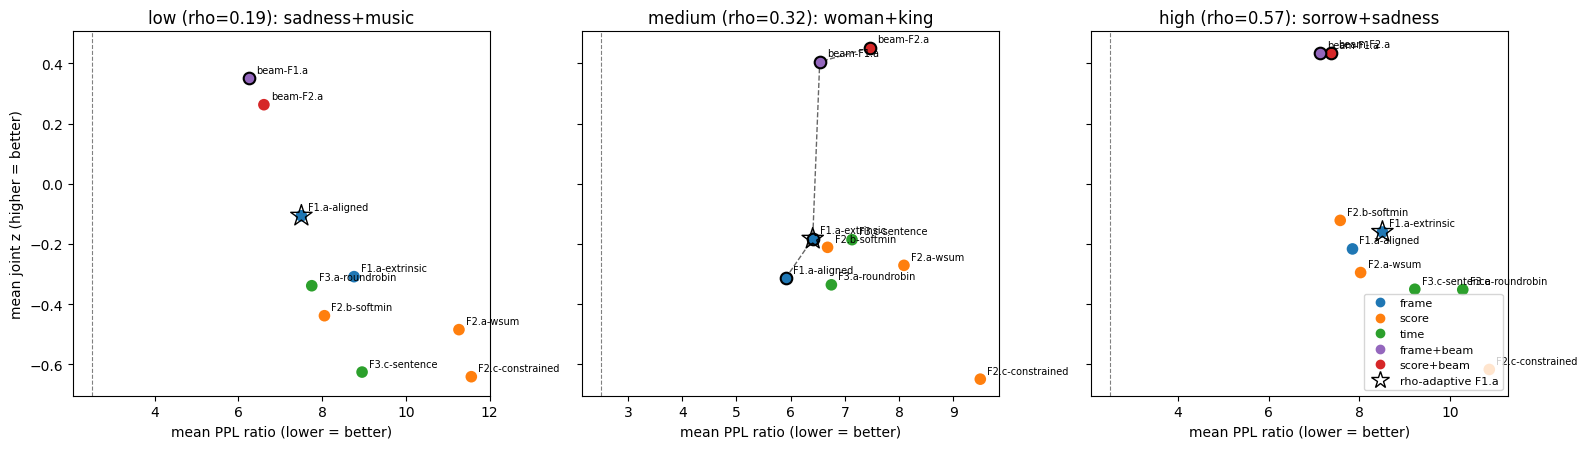

In [8]:
def pareto_front(points: pd.DataFrame) -> pd.DataFrame:
    """Rows not dominated by any other (lower ppl_ratio AND higher joint_z)."""
    keep = []
    for _, row in points.iterrows():
        dominated = (
            (points["ppl_ratio"] <= row["ppl_ratio"])
            & (points["joint_z"] >= row["joint_z"])
            & (
                (points["ppl_ratio"] < row["ppl_ratio"])
                | (points["joint_z"] > row["joint_z"])
            )
        ).any()
        keep.append(not dominated)
    return points[keep].sort_values("ppl_ratio")


family_colors = {
    "frame": "tab:blue",
    "score": "tab:orange",
    "time": "tab:green",
    "frame+beam": "tab:purple",
    "score+beam": "tab:red",
}
ADAPTIVE = {"low": "F1.a-aligned", "medium": "F1.a-extrinsic", "high": "F1.a-extrinsic"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, (stratum, info) in zip(axes, SELECTION.items()):
    cell = summary[summary["stratum"] == stratum]
    front = pareto_front(cell)
    ax.plot(front["ppl_ratio"], front["joint_z"], "k--", lw=1, alpha=0.6, zorder=1)
    for _, row in cell.iterrows():
        ax.scatter(
            row["ppl_ratio"],
            row["joint_z"],
            s=70,
            color=family_colors[row["family"]],
            edgecolor="black" if row["method"] in front["method"].values else "none",
            linewidth=1.5,
            zorder=2,
        )
        ax.annotate(
            row["method"],
            (row["ppl_ratio"], row["joint_z"]),
            textcoords="offset points",
            xytext=(5, 4),
            fontsize=7,
        )
    star = cell[cell["method"] == ADAPTIVE[stratum]]
    ax.scatter(
        star["ppl_ratio"],
        star["joint_z"],
        marker="*",
        s=260,
        facecolor="none",
        edgecolor="black",
        zorder=3,
    )
    ax.set_title(
        f"{stratum} (rho={info['rho']:.2f}): {info['a'].split('.')[0]}+{info['b'].split('.')[0]}"
    )
    ax.set_xlabel("mean PPL ratio (lower = better)")
    ax.axvline(2.5, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("mean joint z (higher = better)")

handles = [
    plt.Line2D([], [], marker="o", ls="", color=color, label=family)
    for family, color in family_colors.items()
] + [
    plt.Line2D(
        [],
        [],
        marker="*",
        ls="",
        markersize=13,
        markerfacecolor="none",
        markeredgecolor="black",
        label="rho-adaptive F1.a",
    )
]
axes[-1].legend(handles=handles, fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig("resources/20_e1_pareto.png", dpi=150)
plt.show()

In [9]:
print("Pareto-front members per stratum:")
for stratum in SELECTION:
    front = pareto_front(summary[summary["stratum"] == stratum])
    members = ", ".join(
        f"{row['method']} (jz={row['joint_z']:.2f}, ppl={row['ppl_ratio']:.1f}x)"
        for _, row in front.iterrows()
    )
    print(f"  {stratum:>6}: {members}")

Pareto-front members per stratum:
     low: beam-F1.a (jz=0.35, ppl=6.3x)
  medium: F1.a-aligned (jz=-0.31, ppl=5.9x), F1.a-extrinsic (jz=-0.18, ppl=6.4x), beam-F1.a (jz=0.41, ppl=6.5x), beam-F2.a (jz=0.45, ppl=7.5x)
    high: beam-F1.a (jz=0.43, ppl=7.1x), beam-F2.a (jz=0.44, ppl=7.4x)


In [10]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


SHOW = ("F1.a-aligned", "F2.b-softmin", "F3.c-sentence", "beam-F1.a")
for stratum in SELECTION:
    for method in SHOW:
        example = next(
            r
            for r in parsed
            if r["config"]["stratum"] == stratum
            and r["config"]["method"] == method
            and "short story" in r["prompt"]
        )
        deltas = {
            name.split(".")[0]: round(v["delta"], 4)
            for name, v in example["expression"].items()
        }
        print(f"[{stratum} / {method}] deltas={deltas}")
        print("   ", answer(example["text"])[:130])
    print()

[low / F1.a-aligned] deltas={'sadness': 0.4957, 'music': -0.481}
    Once, a long-faded wooden box lay hidden deep in an over-grown, abandoned orchards. For as much as anyone
[low / F2.b-softmin] deltas={'sadness': -0.0057, 'music': 0.2375}
    Once, in an old antique clockmaker's shop in Paris's charming Le Quartiers Latin quarter, an old, intricate timepiece
[low / F3.c-sentence] deltas={'sadness': 0.1262, 'music': -1.237}
    Once, on Moon Island (a small specks in an ocean far away) there existed an eccentric inventor. The man spent most
[low / beam-F1.a] deltas={'sadness': 0.6276, 'music': -0.4232}
    Once, a tiny, shimmeringly beautiful bird lived deep in ancient Japan. She flitter-ed and flutter-flutter-ed about the

[medium / F1.a-aligned] deltas={'woman': 1.1656, 'king': 0.7143}
    Once, a young artist lived a mundane office job, stuck behind a screen for most his waking day, dreaming of a different life
[medium / F2.b-softmin] deltas={'woman': -0.0033, 'king': 0.2576}
    O